# Principle and applications of BPCS-Steganography (Bit-Plane Complexity Segmentation)

Implementacja algorytmu z artykułu *Principle and applications of BPCS-Steganography* (Kawaguchi, Eason, 1998).

## 1. Idea

BPCS to metoda ukrywania danych w obrazach cyfrowych o znacznie większej pojemności niż klasyczna steganografia LSB (*Least Significant Bit*). Podczas gdy tradycyjne techniki pozwalają ukryć zazwyczaj 10–15% objętości obrazu nośnego bez widocznych zniekształceń, BPCS osiąga pojemność sięgającą **ok. 50% rozmiaru obrazu**.

### Wykorzystanie ludzkiej percepcji

Metoda opiera się na właściwości ludzkiego układu wzrokowego: człowiek bardzo dobrze dostrzega zmiany w prostych, uporządkowanych kształtach, ale **nie potrafi odróżnić jednego wzoru losowego szumu od innego**.

Zamiast modyfikować wyłącznie najmniej znaczące bity pikseli, autorzy zaproponowali podział każdej płaszczyzny bitowej obrazu na małe fragmenty i zastępowanie tych, które wyglądają jak szum, blokami tajnych danych.

### Jak działa algorytm BPCS

1. **Konwersja na kod Graya (CGC):** Obraz (np. 24-bitowy RGB) jest najpierw przeliczany ze zwykłego zapisu binarnego (PBC) na kod Graya. Eliminuje to problem tzw. klifu Hamminga, gdzie minimalna zmiana jasności (np. z 127 na 128) zmienia wszystkie bity naraz i tworzy sztuczny szum na wyższych płaszczyznach bitowych.
2. **Podział na płaszczyzny bitowe i bloki:** Obraz rozkłada się na osobne warstwy binarne (od najbardziej znaczącego bitu MSB do najmniej znaczącego LSB), a każdą warstwę dzieli na bloki o wymiarach $8 \times 8$ pikseli.
3. **Pomiar złożoności ($\alpha$):** Dla każdego bloku oblicza się współczynnik złożoności $\alpha \in [0, 1]$ jako stosunek liczby zmian koloru (przejść między czernią a bielą w wierszach i kolumnach) do maksymalnej możliwej liczby takich przejść (dla bloku $8 \times 8$ maksimum to 112).
4. **Segmentacja:** Wyznacza się próg złożoności $\alpha_0$ (w artykule najczęściej ok. $0{,}3$). Bloki o $\alpha \le \alpha_0$ uznaje się za **informacyjne** (zawierają strukturę obrazu i pozostają nietknięte), a bloki o $\alpha > \alpha_0$ za **szumopodobne** - można je w całości zastąpić blokami tajnych danych.
5. **Koniugacja (sprzężenie):** Jeśli blok tajnych danych ma zbyt niską złożoność (np. zawiera same zera), wstawienie go w miejsce szumu byłoby widoczne. Algorytm wykonuje więc na nim operację XOR ze wzorem szachownicy, co odwraca jego złożoność ($\alpha^* = 1 - \alpha$). Mapa koniugacji zapisuje, które bloki zostały w ten sposób przekształcone, aby odbiorca mógł je odtworzyć.

### Zastosowania i ograniczenia

- **Zastosowania:** Autorzy wskazują na tajną komunikację, ukrywanie poufnych metadanych (np. danych pacjentów w obrazach medycznych), zabezpieczanie dokumentów oraz tworzenie steganograficznych systemów plików.
- **Ograniczenia:** BPCS wymaga formatów bezstratnych (np. BMP, PNG). Kompresja stratna (np. JPEG) lub drobne modyfikacje obrazu niszczą ukryte dane, ponieważ zmieniają wartości bitów w blokach.

## 2. Przygotowanie danych

Używamy czterech obrazów RGB (`uint8`): sztucznej szachownicy oraz trzech zdjęć z `scikit-image`. Szachownica to celowo **zły nośnik** - składa się z dużych płaskich pól, więc nie ma w niej szumopodobnych bloków. Wymiary niepodzielne przez 8 (np. `cat`) obsługujemy, używając tylko pełnych bloków.

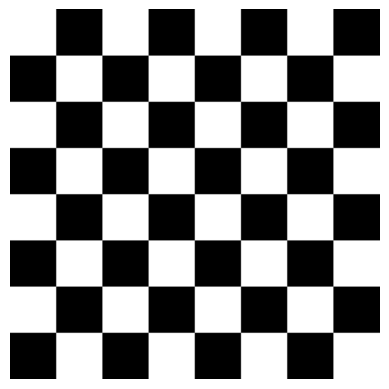

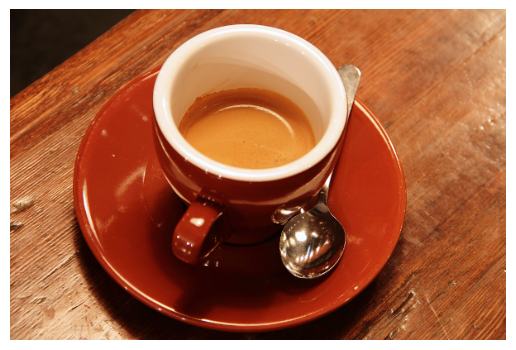

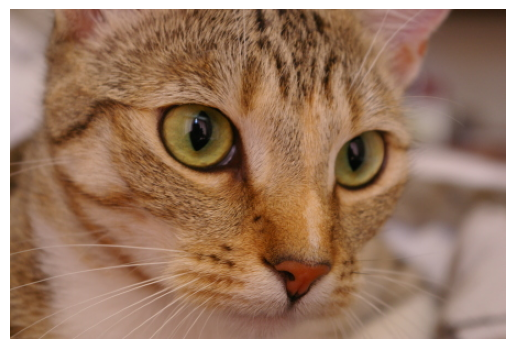

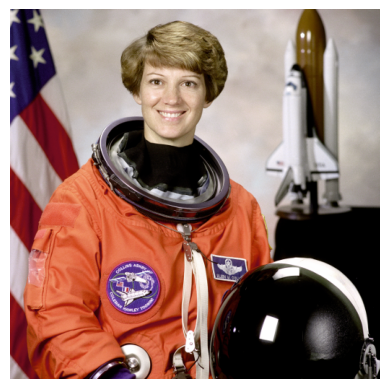

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## 3. Implementacja

### 3.1 Kod Graya i płaszczyzny bitowe

W naturalnym kodzie binarnym mała zmiana jasności może odwrócić wiele bitów naraz (np. `01111111` → `10000000`, tzw. *Hamming cliffs*), przez co płaskie obszary wyglądają na złożone. W kodzie Graya, `g = b ^ (b >> 1)`, sąsiednie wartości różnią się jednym bitem, więc złożoność płaszczyzn lepiej odpowiada rzeczywistej zmienności obrazu.

In [9]:
BLOCK = 8
# Maksymalna liczba zmian 0 <-> 1 w bloku 8x8:
# w poziomie: 8 wierszy * 7 przejść = 56; w pionie: 8 kolumn * 7 przejść = 56; razem = 112
MAX_BORDER = 2 * BLOCK * (BLOCK - 1)  

# Konwertuje wartości pikseli ze zwykłego kodu binarnego (PBC) na kod Graya (CGC).
def pbc_to_cgc(img):
    return img ^ (img >> 1)

# Konwertuje wartości pikseli z kodu Graya (CGC) z powrotem na zwykły kod binarny (PBC).
def cgc_to_pbc(g):
    b = g.copy()
    # Odwrócenie konwersji dla liczb 8-bitowych wymaga kolejnych przesunięć o 1, 2 i 4 bity
    for shift in (1, 2, 4):
        b ^= b >> shift
    return b

# Rozkłada obraz RGB (H, W, 3) na 24 binarne płaszczyzny bitowe w kodzie Graya (24, H8, W8).
# Wymiary H8 i W8 są zaokrąglone w dół do wielokrotności rozmiaru bloku (8).
def to_planes(img):
    h, w = img.shape[0] // BLOCK * BLOCK, img.shape[1] // BLOCK * BLOCK
    g = pbc_to_cgc(img[:h, :w])
    bits = (g[..., None] >> np.arange(8)) & 1                       # (h, w, 3, 8)
    return bits.transpose(2, 3, 0, 1).reshape(24, h, w).astype(np.uint8)

# Składa 24 płaszczyzny bitowe CGC z powrotem w obraz RGB (PBC).
# Ewentualne marginesy poza pełnymi blokami 8x8 kopiuje z oryginalnego obrazu.
def from_planes(planes, img):
    _, h, w = planes.shape
    weights = (1 << np.arange(8)).astype(np.uint8)[None, :, None, None]
    g = (planes.reshape(3, 8, h, w) * weights).sum(axis=1, dtype=np.uint8)   # (3, h, w)
    out = img.copy()
    out[:h, :w] = cgc_to_pbc(g.transpose(1, 2, 0))
    return out


# Testy jednostkowe: weryfikacja pełnej odwracalności konwersji PBC <-> CGC oraz podziału na płaszczyzny
x = np.arange(256, dtype=np.uint8)
assert (cgc_to_pbc(pbc_to_cgc(x)) == x).all()
assert (from_planes(to_planes(imgs_color[1]), imgs_color[1]) == imgs_color[1]).all()

### 3.2 Złożoność i sprzężenie (koniugacja) bloków

**Złożoność bloku** $\alpha$ definiujemy jako liczbę zmian wartości (`0 ↔ 1`) między sąsiednimi pikselami w wierszach i kolumnach ($k$), podzieloną przez maksymalną możliwą liczbę takich zmian ($k_{\max} = 112$ dla bloku $8 \times 8$):

$$\alpha = \frac{k}{k_{\max}}, \qquad 0 \le \alpha \le 1$$

**Sprzężenie (koniugacja)** polega na wykonaniu operacji XOR między blokiem $P$ a wzorem szachownicy $W_c$:

$$P^* = P \oplus W_c$$

Operacja ta ma dwie kluczowe własności:
- **Odwraca złożoność:** $\alpha(P^*) = 1 - \alpha(P)$ — zbyt prosty blok danych (o niskim $\alpha$) staje się szumopodobny.
- **Jest samoodwracalna:** $(P^*)^* = P$ — ponowne wykonanie XOR z $W_c$ przywraca oryginalny blok danych.

In [10]:
# Wzór szachownicy 8x8 (W_c) używany do koniugacji (sprzęgania) prostych bloków
WC = (np.indices((BLOCK, BLOCK)).sum(axis=0) % 2).astype(np.uint8)   # szachownica Wc (0 w lewym górnym rogu)

# Dzieli tablicę płaszczyzn (P, H, W) na siatkę bloków 8x8 o kształcie (P, H/8, W/8, 8, 8).
def to_blocks(planes):
    P, h, w = planes.shape
    return planes.reshape(P, h // BLOCK, BLOCK, w // BLOCK, BLOCK).transpose(0, 1, 3, 2, 4)

# Składa siatkę bloków (P, H/8, W/8, 8, 8) z powrotem w płaszczyzny bitowe (P, H, W).
def from_blocks(blocks):
    P, hb, wb = blocks.shape[:3]
    return blocks.transpose(0, 1, 3, 2, 4).reshape(P, hb * BLOCK, wb * BLOCK)

# Oblicza współczynnik złożoności alfa (0..1) dla dowolnej tablicy bloków o kształcie (..., 8, 8).
# Zlicza przejścia 0 <-> 1 w poziomie (wiersze) oraz w pionie (kolumny).
def complexity(b):
    k = (b[..., 1:] != b[..., :-1]).sum(axis=(-1, -2)) + (b[..., 1:, :] != b[..., :-1, :]).sum(axis=(-1, -2))
    return k / MAX_BORDER

# Wykonuje koniugację (XOR z szachownicą W_c), odwracając złożoność bloku.
def conjugate(b):
    return b ^ WC

# Testy jednostkowe: sprawdzenie własności alfa(P*) = 1 - alfa(P) oraz (P*)* = P
p = np.random.default_rng(0).integers(0, 2, (BLOCK, BLOCK), dtype=np.uint8)
assert np.isclose(complexity(conjugate(p)), 1 - complexity(p))
assert (conjugate(conjugate(p)) == p).all()

### 3.3 Osadzanie danych

Dane zapisywane w obrazie układamy w jeden ciąg bloków $8 \times 8$ o strukturze:

`[nagłówek]` → `[bloki danych]` → `[mapa sprzężeń]`

- **Nagłówek (1 blok = 8 bajtów):** przechowuje dokładną długość tajnej wiadomości w bajtach (64-bitowa liczba całkowita).
- **Bloki danych ($n$ bloków po 8 bajtów):** właściwa wiadomość; każdy blok o złożoności $\alpha < \alpha_0$ jest sprzęgany funkcją `conjugate()`.
- **Mapa sprzężeń:** po 1 bicie na każdy blok danych (1 blok mieści informację dla 64 bloków danych). 
Zarówno nagłówek, jak i mapa sprzężeń są **„wybielane”** (XOR ze strumieniem pseudolosowym zależnym od klucza), aby same były szumopodobne i nieczytelne bez klucza.

#### Kolejność zapisu
Bloki wpisujemy w szumopodobne miejsca obrazu **od najmniej znaczących płaszczyzn bitowych (LSB) ku najbardziej znaczącym (MSB)**, a w obrębie każdej warstwy w kolejności pseudolosowej wyznaczonej przez klucz. Dzięki temu przy częściowym zapełnieniu obrazu modyfikacje trafiają w najmniej widoczne dla oka bity.

Ponieważ każdy wstawiany blok spełnia warunek $\alpha \ge \alpha_0$, zbiór szumopodobnych pozycji po osadzeniu danych jest identyczny jak przed - dekoder znajdzie dokładnie te same miejsca.

In [11]:
import struct


# Konwertuje ciąg bajtów na tablicę bloków bitowych (N, 8, 8), dopełniając zerami do wielokrotności 8 bajtów
def bytes_to_blocks(data):
    data = data + bytes(-len(data) % 8)
    return np.unpackbits(np.frombuffer(data, np.uint8)).reshape(-1, BLOCK, BLOCK)


# Składa tablicę bloków bitowych (N, 8, 8) z powrotem w ciąg bajtów
def blocks_to_bytes(blocks):
    return np.packbits(blocks.reshape(-1)).tobytes()


# „Wybiela” bloki operacją XOR z maską pseudolosową wygenerowaną z klucza i soli (salt)
# Podnosi to złożoność bloków i zabezpiecza nagłówek/mapę przed odczytem bez klucza
def whiten(blocks, key, salt):
    mask = np.random.default_rng([key, salt]).integers(0, 2, blocks.shape, dtype=np.uint8)
    return blocks ^ mask


# Wyznacza listę współrzędnych (płaszczyzna, wiersz_bloku, kolumna_bloku) dla bloków o złożoności >= alpha0
# Pozycje są najpierw tasowane kluczem, a następnie stabilnie sortowane od LSB (0) do MSB (7)
def noise_positions(blocks, key, alpha0):
    pos = np.argwhere(complexity(blocks) >= alpha0)
    pos = pos[np.random.default_rng([key, 2]).permutation(len(pos))]
    # pos[:, 0] % 8 oznacza numer bitu w kanale (0 = LSB, 7 = MSB)
    return pos[np.argsort(pos[:, 0] % 8, kind="stable")]


# Oblicza maksymalną pojemność obrazu w bajtach przy danym progu alpha0,
# uwzględniając miejsce potrzebne na nagłówek (1 blok) oraz mapę sprzężeń (1 blok na 64 bloki danych)
def capacity(img, alpha0=0.3):
    free = len(noise_positions(to_blocks(to_planes(img)), 0, alpha0)) - 1  # -1 blok na nagłówek
    n = max(free, 0) * 64 // 65
    # Dopasowanie liczby bloków danych n tak, aby zmieściła się również ich mapa sprzężeń
    while n > 0 and n + (-(-n // 64)) > free:
        n -= 1
    return n * BLOCK


# Osadza tajne dane (bytes) w obrazie RGB za pomocą algorytmu BPCS i zwraca obraz stego
def embed(img, secret, key=0, alpha0=0.3):
    planes = to_planes(img)
    blocks = to_blocks(planes)
    pos = noise_positions(blocks, key, alpha0)

    # 1. Przygotowanie bloków danych i sprzężenie tych, które są zbyt proste
    payload = bytes_to_blocks(secret)
    n = len(payload)
    simple = complexity(payload) < alpha0
    payload = np.where(simple[:, None, None], conjugate(payload), payload)

    # 2. Budowa mapy sprzężeń (1 bit na blok danych, dopełnienie do pełnych bloków 64-bitowych)
    cmap = np.pad(simple.astype(np.uint8), (0, -n % 64)).reshape(-1, BLOCK, BLOCK)

    # 3. Utworzenie nagłówka (długość danych jako uint64) i wybielenie nagłówka oraz mapy
    header = whiten(bytes_to_blocks(struct.pack("<Q", len(secret))), key, 0)
    cmap = whiten(cmap, key, 1)

    # Kontrola, czy wybielony nagłówek i mapa przekraczają próg złożoności alpha0
    if (complexity(np.concatenate([header, cmap])) < alpha0).any():
        raise ValueError("Nagłówek lub mapa są zbyt proste — zmień klucz.")

    # 4. Złączenie strumienia i wpisanie go w wyznaczone szumopodobne pozycje
    stream = np.concatenate([header, payload, cmap])
    if len(stream) > len(pos):
        raise ValueError(f"Za dużo danych: potrzeba {len(stream)} bloków, dostępne {len(pos)}.")

    blocks[tuple(pos[:len(stream)].T)] = stream
    return from_planes(from_blocks(blocks), img)

### 3.4 Odczyt

Dekoder wykonuje te same kroki w odwrotnej kolejności: wyznacza szumopodobne bloki w obrazie z danymi (CGC), czyta nagłówek, następnie bloki danych i mapę sprzężeń, po czym sprzęga z powrotem te bloki, które były sprzężone. Bez właściwego klucza (i progu $\alpha_0$) pozycje, nagłówek i mapa są nieczytelne.

In [12]:
# Odczytuje tajne dane (bytes) z obrazu stego przy użyciu podanego klucza i progu alpha0
def extract(stego, key=0, alpha0=0.3):
    blocks = to_blocks(to_planes(stego))
    pos = noise_positions(blocks, key, alpha0)
    if len(pos) == 0:
        raise ValueError("Obraz nie zawiera szumopodobnych bloków.")

    # Pomocniczo pobiera wycinek bloków z pozycji od a do b
    def get(a, b):
        return blocks[tuple(pos[a:b].T)]

    # 1. Odczyt długości wiadomości z pierwszego bloku (nagłówka)
    length = struct.unpack("<Q", blocks_to_bytes(whiten(get(0, 1), key, 0)))[0]
    if length > len(pos) * BLOCK:
        raise ValueError("Brak danych albo zły klucz / próg.")

    # 2. Obliczenie liczby bloków danych (n) i odczyt mapy sprzężeń
    n = -(-length // 8)
    cmap_blocks = -(-n // 64)
    cmap = whiten(get(1 + n, 1 + n + cmap_blocks), key, 1).reshape(-1)[:n].astype(bool)

    # 3. Odczyt bloków danych i cofnięcie koniugacji tam, gdzie mapa ma wartość True
    data_blocks = get(1, 1 + n)
    payload = np.where(cmap[:, None, None], conjugate(data_blocks), data_blocks)

    # 4. Złożenie bloków w bajty i przycięcie do dokładnej długości wiadomości
    return blocks_to_bytes(payload)[:length]

## 4. Użycie

Dla każdego obrazu testowego:
1. Obliczamy maksymalną pojemność przy $\alpha_0 = 0{,}3$ i osadzamy dane zajmujące **50% pojemności** (`FILL = 0.5`).
2. Generujemy dane testowe jako losowe bajty (imitujące dane skompresowane lub zaszyfrowane), w których **pierwsze 10% stanowią zera** - wymusza to działanie mechanizmu koniugacji prostych bloków.
3. Weryfikujemy bezbłędność odczytu i mierzymy jakość obrazu stego za pomocą metryki **PSNR** (*Peak Signal-to-Noise Ratio*, w decybelach - wartości powyżej ok. 35-40 dB są zazwyczaj nieodróżnialne dla ludzkiego oka).

### 4.1. Losowe dane

checkerboard | pojemność:        0 B — obraz nie ma szumopodobnych bloków
coffee       | pojemność:  312,336 B (43.4%) | sprzężono: 1,952 bloków | PSNR: 45.0 dB | odczyt poprawny: True
cat          | pojemność:  162,680 B (40.1%) | sprzężono: 1,017 bloków | PSNR: 45.5 dB | odczyt poprawny: True
astronaut    | pojemność:  297,760 B (37.9%) | sprzężono: 1,861 bloków | PSNR: 45.7 dB | odczyt poprawny: True


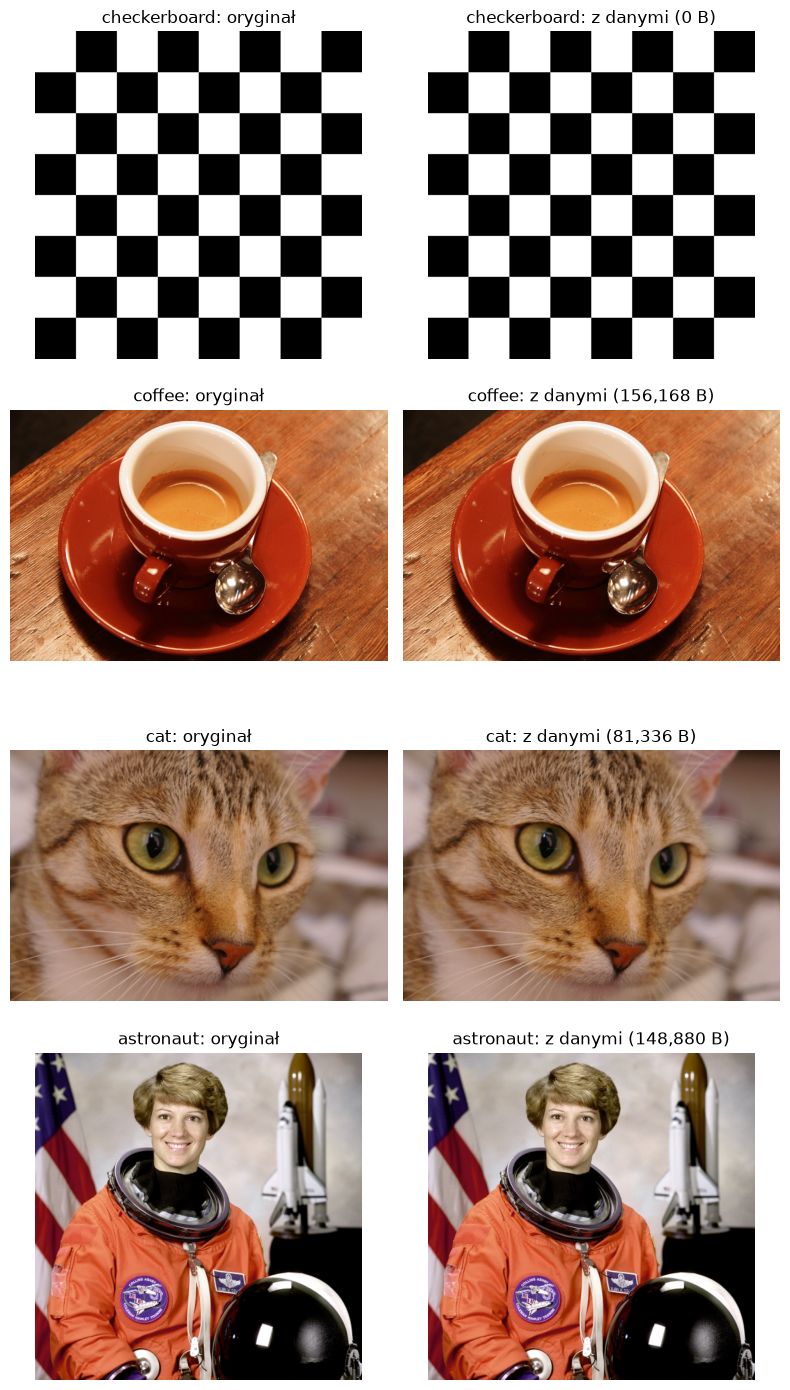

Zły klucz: Brak danych albo zły klucz / próg.


In [13]:
# Oblicza współczynnik PSNR (w dB) między obrazem oryginalnym a zmodyfikowanym
def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)


# Parametry eksperymentu: klucz, próg złożoności i stopień zapełnienia pojemności
KEY, ALPHA0, FILL = 1234, 0.3, 0.5
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 3.5 * len(imgs_color)))

for img, name, (ax_orig, ax_stego) in zip(imgs_color, image_names, axes):
    # Wyznaczenie pojemności i rozmiaru wiadomości (wyrównanego do wielokrotności 8 bajtów)
    cap = capacity(img, ALPHA0)
    size = int(cap * FILL) // 8 * 8

    # Generowanie tajnych danych: 90% losowych bajtów + 10% zer (proste bloki do sprzężenia)
    secret = bytearray(rng.bytes(size))
    secret[: size // 10] = bytes(size // 10)
    secret = bytes(secret)

    if cap:
        stego = embed(img, secret, KEY, ALPHA0)
        ok = extract(stego, KEY, ALPHA0) == secret
        n_conj = int((complexity(bytes_to_blocks(secret)) < ALPHA0).sum())
        print(
            f"{name:12s} | pojemność: {cap:>8,d} B ({cap / img.size:5.1%}) | "
            f"sprzężono: {n_conj:>5,d} bloków | PSNR: {psnr(img, stego):4.1f} dB | "
            f"odczyt poprawny: {ok}"
        )
    else:
        stego = img
        print(f"{name:12s} | pojemność:        0 B — obraz nie ma szumopodobnych bloków")

    # Wizualne porównanie oryginału i obrazu z ukrytymi danymi
    ax_orig.imshow(img)
    ax_orig.set_title(f"{name}: oryginał")
    ax_stego.imshow(stego)
    ax_stego.set_title(f"{name}: z danymi ({len(secret):,d} B)")
    ax_orig.axis("off")
    ax_stego.axis("off")

plt.tight_layout()
plt.show()

# Test bezpieczeństwa: próba odczytu z błędnym kluczem powinna zakończyć się błędem
try:
    extract(stego, KEY + 1, ALPHA0)
except ValueError as e:
    print("Zły klucz:", e)

### 4.2. Obraz w obrazie

Pojemność nośnika: 312,336 B | Rozmiar tajnego obrazu: 27,833 B


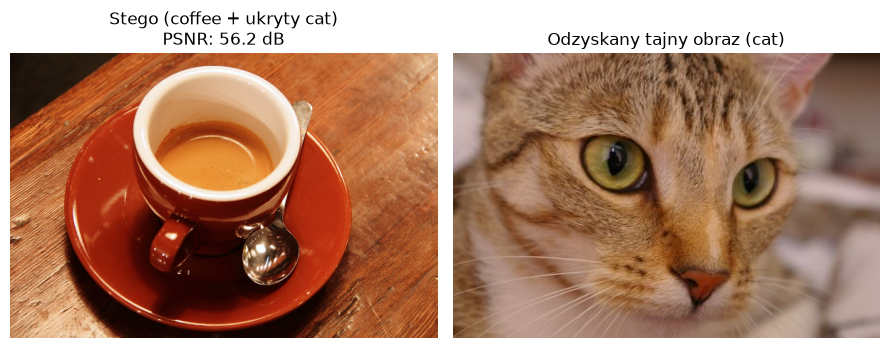

In [14]:
# Wybieramy nośnik (coffee) i tajny obraz do ukrycia (cat, lekko zmniejszony lub zapisany jako JPEG)
vessel = imgs_color[1]  # coffee
secret_img = imgs_color[2]  # cat

# Zamiana tajnego obrazu na bajty (JPEG świetnie kompresuje, dzięki czemu zmieści się z zapasem)
buf = io.BytesIO()
Image.fromarray(secret_img).save(buf, format="JPEG", quality=85)
secret_bytes = buf.getvalue()

print(f"Pojemność nośnika: {capacity(vessel, ALPHA0):,d} B | Rozmiar tajnego obrazu: {len(secret_bytes):,d} B")

# Osadzenie i odczyt
stego = embed(vessel, secret_bytes, key=KEY, alpha0=ALPHA0)
recovered_bytes = extract(stego, key=KEY, alpha0=ALPHA0)
recovered_img = np.array(Image.open(io.BytesIO(recovered_bytes)))

# Wyświetlenie: nośnik z ukrytym kotem oraz odzyskany kot
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(stego)
axes[0].set_title(f"Stego (coffee + ukryty cat)\nPSNR: {psnr(vessel, stego):.1f} dB")
axes[1].imshow(recovered_img)
axes[1].set_title("Odzyskany tajny obraz (cat)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3. Tajna wiadomość

Rozmiar pliku: 1,903 B -> po kompresji: 1,115 B
Odczyt w 100% zgodny z oryginałem: True


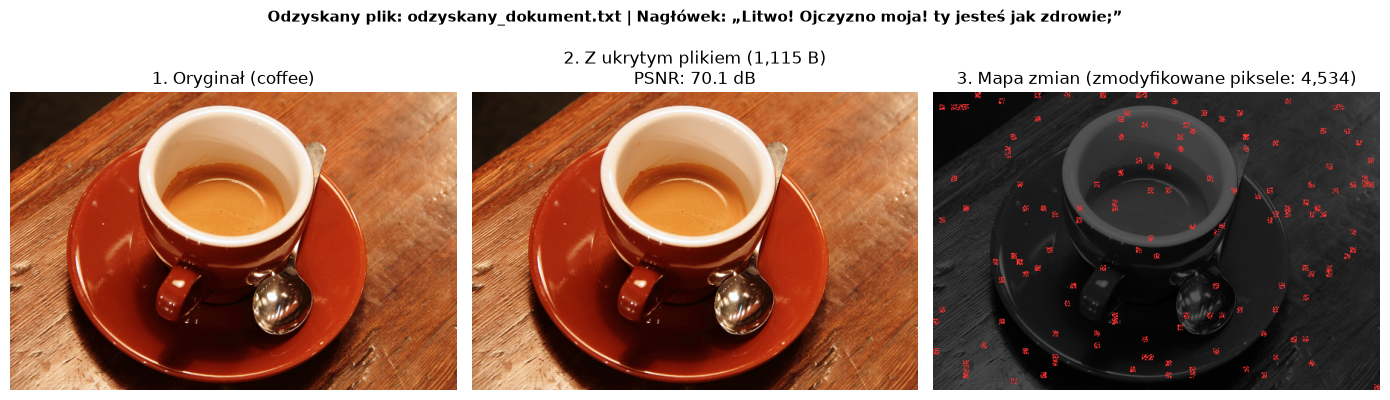

In [19]:
with open("tajny_dokument.txt", "rb") as f:
    raw_bytes = f.read()

secret_bytes = zlib.compress(raw_bytes)
vessel = imgs_color[1]  # coffee

# 3. Osadzenie danych w obrazie i odczyt
stego = embed(vessel, secret_bytes, key=KEY, alpha0=ALPHA0)
recovered_bytes = extract(stego, key=KEY, alpha0=ALPHA0)
recovered_raw = zlib.decompress(recovered_bytes)

# 4. Zapis odzyskanego pliku na dysk i weryfikacja zgodności
with open("odzyskany_dokument.txt", "wb") as f:
    f.write(recovered_raw)

print(f"Rozmiar pliku: {len(raw_bytes):,d} B -> po kompresji: {len(secret_bytes):,d} B")
print(f"Odczyt w 100% zgodny z oryginałem: {recovered_raw == raw_bytes}")

# 5. Przygotowanie mapy zmian (podświetlenie zmodyfikowanych pikseli na czerwono)
diff_mask = np.any(vessel != stego, axis=-1)
gray = vessel.mean(axis=-1) * 0.35
highlight = np.stack([gray, gray, gray], axis=-1).astype(np.uint8)
highlight[diff_mask] = [255, 50, 50]

# 6. Wizualizacja 3 paneli
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(vessel)
axes[0].set_title("1. Oryginał (coffee)")

axes[1].imshow(stego)
axes[1].set_title(f"2. Z ukrytym plikiem ({len(secret_bytes):,d} B)\nPSNR: {psnr(vessel, stego):.1f} dB")

axes[2].imshow(highlight)
axes[2].set_title(f"3. Mapa zmian (zmodyfikowane piksele: {diff_mask.sum():,d})")

for ax in axes:
    ax.axis("off")

# Podgląd pierwszej linijki odzyskanego pliku nad wykresami
first_line = recovered_raw.decode("utf-8").splitlines()[0]
fig.suptitle(f"Odzyskany plik: odzyskany_dokument.txt | Nagłówek: „{first_line}”", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()